# 12 Rainfall at Tule Pond and the onset seasonality

```
Author: Danielle Lindsay
Environment: opera_disp_feb13. Run time: seconds.
```

**What this notebook does.**

1. **Daily rainfall at Tule Pond** (sections 3 and 4). The two NOAA GHCN-daily gauges nearest Tule Pond (Menne et
   al. 2012), Fremont and Newark, are joined day by day, Fremont first, without rescaling; the agreement of the two
   gauges where they overlap is printed. Newark is a morning-observer COOP gauge and is shifted one day earlier onto
   the midnight basis. The shift is checked against Hayward Air Terminal (18 km), a midnight-basis gauge used only
   for this check, and on a dated storm. Over the InSAR events the record is Fremont alone (asserted), so the storm
   analysis, which uses only the InSAR events, reads a single gauge; Newark fills the other years. The water year
   runs from 1 October to 30 September and is named by the calendar year in which it ends (section 2). The gauge
   files in `external_inputs/GHCN_daily` (`common_paths["ghcn_dir"]`) are fixed inputs. A missing file stops the
   notebook unless `TULEPOND_DOWNLOAD_GHCN=1` is set, which downloads it.
2. **Event table** (sections 5 and 6). The InSAR events and the HRKT events of the bimonthly era, each with its onset
   window, step and the rainfall around the window (`event_table.csv`).
3. **Onset seasonality** (section 6). Every season-resolved onset (the InSAR windows and the bimonthly-era array
   windows, all `aa_dense_window_days` (130 d) or less) is counted against the wet season, October to April
   (`TulePond_filepaths.wet_season_months`, the same months as the wet season of the forecast in 13_forecast). The
   panel products of the paper's Fig 3A and 3B are saved for 14_paper_figures, which draws the figure (section 11).
4. **Rainfall conditioning of the onsets** (sections 7 to 9). For each onset window: the water-year rainfall
   accumulated by then, the lag after fixed cumulative thresholds (rule A) and the lag after the first storm of the
   water year (rule B). Then a test of whether an InSAR onset falls within X days after a 3-day rainfall total of at
   least Z mm more often than a random day of the same season in the same water year. The test uses only the five
   InSAR onsets and the Fremont gauge. Z and X are swept over 16 settings and the p value is corrected for the
   search over the settings. The quantities quoted in the prediction statement of 13_forecast are written to
   `rain_conditioning_summary.csv` (section 10).

**Day convention.** This notebook defines the rain day of each onset window, and 14_paper_figures reads the days it
writes. InSAR acquisitions are timed in UTC (the zero-Doppler times of the OPERA granules, `acquisition_times.csv` of
03). The ascending pass
(frame 09157) is at about 02:08 UTC, the evening of the previous local day (18:08 PST). The descending pass (frame
11115) is at about 14:08 UTC, the morning of the same local day (06:08 PST). Rainfall is booked by the local day:
Fremont is on the midnight basis and is not shifted, and Newark, a morning observer, is shifted by -1 d (both
checked). Each InSAR onset window is therefore converted to local calendar days before it is compared with the
rainfall. The first day is the local day of the last acquisition before the step (`onset_lo_utc` of 04), the last
day the local day of the first acquisition after it (`onset_hi_utc`). The window includes both days. The local day is
computed in `rain_day_timezone` and must equal the day in standard time (UTC-8) (asserted; no acquisition is near
local midnight, so daylight saving cannot change it). Array windows are survey days, which are already local. The
renewal forecast of 13_forecast works in continuous decimal years and is not affected, since the offsets are hours.

**Inputs**: the three GHCN-daily gauge files (two in the composite, Hayward as the check gauge); 04
`creep_events.csv` (InSAR onset windows, `onset_lo` to `onset_hi`, and their exact UTC ends `onset_lo_utc` and
`onset_hi_utc`); 11 `hrkt_aa_events.csv` (array onset windows with the same columns, plus `onset_mid`, the window
midpoint, used only for plot positions) and `aa_insar_stacks.csv` (the start of the InSAR record); the HRKT array
file (the end of its bimonthly surveys); 03 `acquisition_times.csv` (the UTC time and track of every acquisition).

**Outputs** (`outputs/12_rain_seasonality/`): `tulepond_daily_precip.csv`; `wateryear_totals.csv`;
`event_table.csv` (window ends as local days, with their basis in `window_day_basis`); the Fig 3 panel products
`fig3_rain_panel.npz` (with the wet-season months) and `fig3_onset_windows.csv` (one row per onset window of both
catalogues, read by 14_paper_figures, with `onset_lo`, `onset_hi`, `onset_mid` for the plot position, the window as local
calendar days `day_lo` and `day_hi`, the UTC acquisitions `utc_lo` and `utc_hi` that bound an InSAR window, and the
day of water year of each end); the rainfall conditioning `precip_conditioning_{events,thresholds}.csv`;
`rain_total_sweep.csv` (the 16 settings of the 3-day rainfall-total test with hits, null expectation and p);
`rain_conditioning_summary.csv` (one row per quantity quoted in the prediction statement of 13_forecast, with name,
value, unit and description); the stats sidecar `12_rain_stats.txt`; registry rows `12_*`.

**Figures**: the rainfall conditioning with the p of every setting of the rainfall-total test
(`figS_precip_conditioning_bestY<Y>mm_rain3d_sweep16_nnull<n>`, supplement).

**What to check.** The Fremont/Newark water-year ratio over the complete years (printed, section 3; no rescaling).
The shifted Newark series agrees better with Hayward on storm days and books the 11 December 2014 storm on the same
day (both asserted, section 4). Every InSAR onset window and the 30 days before it are on Fremont alone (asserted,
section 5), so the Newark fill does not enter the InSAR analysis. The InSAR windows in local days are printed beside
the UTC days in section 5; a window whose first or last acquisition is ascending starts or ends one day earlier. The
onset windows are counted against the wet season by window, not by midpoint, as wholly inside, partly inside or
wholly outside (`12_n_wet_<season>_*`, e.g. `12_n_wet_oct_apr_inside`). The first and last day of the InSAR onset
windows on the water year are registered (`12_insar_onset_earliest`, `12_insar_onset_latest`). For the
rainfall-total test, the value to quote is the search-corrected p (`12_rain_sweep_p_search_paid`), not the p of the
best setting alone (`12_rain_sweep_best_p`).

## 1. Imports and settings

The gauges, the wet season, the test settings, the figure settings and the input files. The registry records the
input files.

In [1]:
import calendar
import os
import urllib.request

import insar_utils as utils
from TulePond_filepaths import common_paths, paths_out, repo_dir, forecast_issue_date, rain_total_days, rain_total_mm
from TulePond_filepaths import wet_season_months as wet_season_first_last, aa_dense_window_days, loma_prieta_yr

import numpy as np                               # Matrix calculations
import pandas as pd                              # Tables
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

In [2]:
notebook = "12_rain_seasonality"
out_dir = os.path.join(common_paths["out_dir"], notebook)
fig_dir = common_paths["fig_dir"]
os.makedirs(out_dir, exist_ok=True)
os.makedirs(fig_dir, exist_ok=True)


# the gauges: id -> (short name, role in the composite, day shift for morning-observer COOP gauges).
# The composite uses the two gauges nearest Tule Pond (4 and 7 km); Hayward Air Terminal (18 km) is the
# midnight-basis reference for the Newark observation-time check only.
ncei = "https://www.ncei.noaa.gov/data/global-historical-climatology-network-daily/access/{sid}.csv"
download_missing = os.environ.get("TULEPOND_DOWNLOAD_GHCN", "0") == "1"   # 1: download a missing gauge file (the files are fixed inputs)
stations = {"USC00043244": ("FREMONT", "composite-1", 0),      # COOP but on the midnight basis (checked against Hayward)
            "USC00046144": ("NEWARK", "composite-2", -1),      # COOP, morning observer (checked on the 11 Dec 2014 storm below)
            "USW00093228": ("HAYWARD_AT", "check only", 0)}    # ASOS, midnight basis: the reference for the Newark shift check
composite = ["FREMONT", "NEWARK"]
tulepond = (37.557, -121.970)      # section centre (lat, lon)
t_start = "1978-10-01"             # start of WY1979 (first HRKT survey 1979.7)
series_end = pd.Timestamp(forecast_issue_date)   # the rain series ends at the forecast issue date (a fixed end, for reproducibility)
max_missing_days = 20              # a water year with at most this many missing days is "complete"
min_gauge_days = 350               # gauge comparison: water years in which both gauges reported on at least this many days
storm_day_mm = 10.0                # gauge comparison: days on which either gauge has at least this much rain
complete_wy = (1980, 2025)         # the complete water years the rain climatology is quoted over
insar_rain_check_days = 30         # single-gauge check: each InSAR window and this many days before it must be Fremont alone

# the day convention (header): InSAR acquisitions are in UTC, rainfall is booked by the local day
rain_day_timezone = "America/Los_Angeles"   # the local day of the gauges
rain_day_standard_offset_h = -8             # local standard time (PST); the local day must be the same (asserted)

# the seasonality
resolvable_days = aa_dense_window_days   # array windows longer than this (d) do not constrain the season (TulePond_filepaths: the bimonthly era of 11)
# the wet season, (first month, last month), October to April: one definition for this onset count and the forecast
# window of 13_forecast (TulePond_filepaths.wet_season_months); 13_forecast checks it against the months saved here
wet_season_source = "TulePond_filepaths.wet_season_months"
assert len(wet_season_first_last) == 2 and all(int(m) == m and 1 <= m <= 12 for m in wet_season_first_last), \
    f"wet_season_months must be (first month, last month), got {wet_season_first_last}"
first_wet_month, last_wet_month = (int(m) for m in wet_season_first_last)
wet_season_months = []                     # the months of the season in order, wrapping across the new year
for k in range((last_wet_month - first_wet_month) % 12 + 1):
    wet_season_months.append((first_wet_month - 1 + k) % 12 + 1)
wet_season_tag = f"{calendar.month_abbr[first_wet_month].lower()}_{calendar.month_abbr[last_wet_month].lower()}"   # in the registry keys
wet_season_text = f"{calendar.month_name[first_wet_month]} to {calendar.month_name[last_wet_month]}"
print(f"wet season {wet_season_text}, months {wet_season_months} ({wet_season_source})")
density_days = 7           # Fig 3B: running rainfall total (days)
density_max = 80           # ... mm at full colour
rain_colours = ["#FFFFFF", "#C6DBEF", "#4292C6", "#08306B"]      # sequential blues for the rainfall (no other blue on the panel)
insar_bar_colour = "#D55E00"      # Okabe-Ito vermillion
x0, x1 = 1979.0, 2026.5           # the time axis of Fig 3: the HRKT record starts 1979.7
loma_prieta = loma_prieta_yr      # 17 Oct 1989 (TulePond_filepaths), saved for Fig 3A

# the rainfall conditioning (sections 7 to 9)
y_grid = [50, 75, 100, 125, 150, 175, 200, 250, 300, 400]   # WY cumulative thresholds, mm (rule A)
z_grid = [15, 20, 25, 30, 40, 50, 75]                       # first-storm sizes (3-day totals), mm (rule B)
rain_total_grid_mm = [20, 30, 40, 50]                       # rainfall-total test: 3-day rainfall total of at least Z mm ...
rain_lag_grid_d = [7, 14, 21, 30]                           # ... within X days before the InSAR onset
n_draws = 2000               # rainfall-total test: onset draws per InSAR event, uniform over the days of its window
n_null = 20000               # rainfall-total test: null realisations (each event in its own water year, on a day of the onset season)
rain_test_seed = 7           # seed of the random-number generator of the rainfall-total test

# the InSAR stacks at the six arrays (11); only the first HRKT date is used here (the start of the InSAR record for Fig 3A)
stacks_file = os.path.join(paths_out["11_alignment_arrays"], "aa_insar_stacks.csv")
hrkt_file = os.path.join(common_paths["aa_dir"], "HRKT.csv")
events_file = os.path.join(paths_out["04_event_detection"], "creep_events.csv")
aa_events_file = os.path.join(paths_out["11_alignment_arrays"], "hrkt_aa_events.csv")
acquisition_times_file = os.path.join(paths_out["03_creep_timeseries"], "acquisition_times.csv")   # UTC time of every acquisition

REG = utils.Registry(notebook, common_paths, repo_dir)
gauge_files = []
for sid in stations:
    gauge_files.append(os.path.join(common_paths["ghcn_dir"], f"{sid}.csv"))
REG.inputs(events_file, aa_events_file, stacks_file, hrkt_file, *gauge_files, acquisition_times_file)

wet season October to April, months [10, 11, 12, 1, 2, 3, 4] (TulePond_filepaths.wet_season_months)
Registry for 12_rain_seasonality: run 14ec55c6, git 9282cd7


## 2. Functions: dates, water years and the local day of an acquisition

A time $t$ (UTC) has the decimal year of the whole project (`insar_utils.decimal_years`),

$$y = 2000 + \frac{t - t_{2000}}{365.25\ \mathrm{d}},$$

where $t_{2000}$ is 1 January 2000, 00:00 UTC, so that a difference of decimal years times 365.25 is the exact
number of days. The water year of a day $d$ in calendar year $Y$ is

$$\mathrm{WY}(d) = \begin{cases} Y + 1 & \text{if the month of } d \text{ is October or later,} \\ Y & \text{otherwise,} \end{cases}$$

so water year $N$ runs from 1 October of $N - 1$ to 30 September of $N$. The day of the water year is

$$D(d) = d - O_{\mathrm{WY}(d)} + 1,$$

where $O_N$ is 1 October of year $N - 1$, so that 1 October is day 1. A decimal year is first turned into its nearest
calendar day, so every day of the water year in this notebook comes from the same calendar.

The InSAR onset windows run between the exact UTC times of their bounding acquisitions (`onset_lo_utc` and
`onset_hi_utc` of 04, from the OPERA zero-Doppler times in `acquisition_times.csv` of 03). The rain day of a UTC
time is its date in `rain_day_timezone`, which must equal the date of the UTC time minus 8 h (asserted).

The InSAR step errors of 04 are 95 % bootstrap bounds; they are turned into 1 sigma as
$\sigma = (b_\mathrm{hi} - b_\mathrm{lo}) / 3.92$, where $b_\mathrm{lo}$ and $b_\mathrm{hi}$ are the bounds (mm), since a
normal distribution has 95 % of its mass within $\pm 1.96\sigma$ of the mean.

In [3]:
def decyear(dates):
    """Decimal year of each date or time (`insar_utils.decimal_years`).

    Parameters
    ----------
    dates : array-like of dates

    Returns
    -------
    pandas.Index
        Decimal years.
    """
    return pd.Index(utils.decimal_years(dates))


def to_date(decimal_years):
    """Calendar day nearest to each decimal year (an acquisition's own day, not the day before).

    Parameters
    ----------
    decimal_years : float or array-like

    Returns
    -------
    pandas.DatetimeIndex
    """
    out = []
    for value in np.atleast_1d(decimal_years):
        out.append(utils.decimal_year_to_day(value))
    return pd.DatetimeIndex(out)


def water_year(dates):
    """Water year of each date (1 October of N - 1 to 30 September of N is water year N).

    Parameters
    ----------
    dates : array-like of dates

    Returns
    -------
    pandas.Index
        Water years.
    """
    dates = pd.DatetimeIndex(dates)
    return dates.year + (dates.month >= 10).astype(int)


def dowy(dates):
    """Day of the water year of each date (1 October is day 1).

    Parameters
    ----------
    dates : array-like of dates

    Returns
    -------
    pandas.Index
        Days of the water year.
    """
    dates = pd.DatetimeIndex(dates)
    wy_start = pd.to_datetime((water_year(dates) - 1).astype(str) + "-10-01")
    return (dates - wy_start).days + 1


def dowy_frac(decimal_years):
    """Day of the water year (1 October is day 1) of decimal years, through their calendar day.

    Parameters
    ----------
    decimal_years : float or array-like

    Returns
    -------
    numpy.ndarray
    """
    return np.asarray(dowy(to_date(decimal_years)))


def dowy_of(date):
    """Day of the water year (1 October is day 1) and water year of one date.

    Parameters
    ----------
    date : pandas.Timestamp

    Returns
    -------
    day, water_year : int
    """
    return int(dowy([date])[0]), int(water_year([date])[0])


def dowy_label(day):
    """A day of the water year as 'Mon DD' ('--' if undefined).

    Parameters
    ----------
    day : float
        Day of the water year.

    Returns
    -------
    str
    """
    if not np.isfinite(day):
        return "--"
    return (pd.Timestamp("2000-10-01") + pd.Timedelta(days=int(day) - 1)).strftime("%b %d")


def sigma_from_ci95(lo, hi):
    """1 sigma from a 95 % interval, which for a normal distribution spans the mean +/- 1.96 sigma.

    Parameters
    ----------
    lo, hi : float
        Bounds of the 95 % interval.

    Returns
    -------
    float
        (hi - lo) / 3.92.
    """
    return (hi - lo) / 3.92


def window_length_days(window):
    """Length of an onset window (d): between the exact UTC acquisition times (InSAR) or the survey days (array).

    Parameters
    ----------
    window : namedtuple
        A row of `onset_days` (section 6).

    Returns
    -------
    float
    """
    if pd.notna(window.utc_lo):
        return (window.utc_hi - window.utc_lo) / pd.Timedelta(days=1)
    return (window.onset_hi - window.onset_lo) * 365.25


def local_day(utc_time):
    """Local calendar day (the rain day) of a UTC time; it must equal the day in standard time (asserted).

    Parameters
    ----------
    utc_time : pandas.Timestamp

    Returns
    -------
    pandas.Timestamp
        The local day at midnight.
    """
    local = pd.Timestamp(utc_time).tz_localize("UTC").tz_convert(rain_day_timezone).tz_localize(None).normalize()
    standard = (pd.Timestamp(utc_time) + pd.Timedelta(hours=rain_day_standard_offset_h)).normalize()
    assert local == standard, f"{utc_time} UTC is near local midnight: its rain day depends on daylight saving"
    return local


def insar_local_window(utc_lo, utc_hi):
    """An InSAR onset window as local calendar days, both included (the day convention in the header).

    The first day is the local day of the last acquisition before the step, the last day the local day of the first
    acquisition after it.

    Parameters
    ----------
    utc_lo, utc_hi : pandas.Timestamp
        Exact UTC times of the bounding acquisitions (`onset_lo_utc`, `onset_hi_utc` of 04).

    Returns
    -------
    day_lo, day_hi : pandas.Timestamp
        First and last local day.
    track_lo, track_hi : str
        The tracks of the bounding acquisitions.
    """
    track_lo = track_of[utc_lo]
    track_hi = track_of[utc_hi]
    day_lo = local_day(utc_lo)
    day_hi = local_day(utc_hi)
    assert day_lo <= day_hi, f"window {utc_lo}..{utc_hi} is empty in local days"
    return day_lo, day_hi, track_lo, track_hi

## 3. The daily rain composite

GHCN-daily reports precipitation in tenths of a millimetre; it is converted to mm. The composite takes one value per
day,

$$P(d) = \begin{cases} P_F(d) & \text{if Fremont reported on day } d, \\ P_N(d) & \text{otherwise,} \end{cases}
\qquad P_N(d) = P_N^\mathrm{pub}(d + 1),$$

where $P$ is the daily rainfall (mm), $P_F$ the Fremont series, $P_N$ the Newark series shifted one day earlier onto
the midnight basis (section 4) and $P_N^\mathrm{pub}$ the Newark series as published. Days with neither gauge are
missing. The water-year totals table records which gauges made each year and how many days are missing; a water
year with at most `max_missing_days` (20) missing days is complete.

The gauges are compared where they overlap. For each pair, the ratio of the water-year totals is taken over the
water years in which both reported on at least `min_gauge_days` (350) days, and the Pearson correlation of the daily
totals over the days on which either gauge has at least `storm_day_mm` (10 mm). The rainfall climatology (median, 10th
and 90th percentiles of the water-year totals) is quoted over the complete water years of `complete_wy`
(1980 to 2025). Gauge distances use a flat earth with 111.19 km per degree of latitude and $111.19 \cos\varphi$ km
per degree of longitude, where $\varphi$ is the latitude of Tule Pond.

In [4]:
def fetch(sid):
    """One GHCN-daily gauge as a daily series from t_start, with its metadata.

    The file is a fixed input; a missing file stops the notebook unless TULEPOND_DOWNLOAD_GHCN=1. The day shift of
    the gauge in `stations` is applied.

    Parameters
    ----------
    sid : str
        GHCN station ID.

    Returns
    -------
    series : pandas.Series
        Daily precipitation (mm), indexed by day.
    info : dict
        Name, latitude, longitude, first and last day.
    """
    path = os.path.join(common_paths["ghcn_dir"], f"{sid}.csv")
    if not os.path.exists(path):
        assert download_missing, f"missing gauge file {path}; set TULEPOND_DOWNLOAD_GHCN=1 to download it from {ncei.format(sid=sid)}"
        print("downloading", sid)
        urllib.request.urlretrieve(ncei.format(sid=sid), path)
    assert os.path.getsize(path) >= 1000, f"{path} is truncated ({os.path.getsize(path)} bytes)"
    table = pd.read_csv(path, usecols=["DATE", "LATITUDE", "LONGITUDE", "NAME", "PRCP"], low_memory=False)
    table["DATE"] = pd.to_datetime(table.DATE)
    table = table[table.DATE >= t_start]
    info = dict(name=table.NAME.iloc[0], lat=float(table.LATITUDE.iloc[0]), lon=float(table.LONGITUDE.iloc[0]),
                first=table.DATE.min().date(), last=table.DATE.max().date())
    series = table.set_index("DATE").PRCP / 10.0          # tenths of mm -> mm
    series = series[~series.index.duplicated()]
    day_shift = stations[sid][2]
    if day_shift:
        series.index = series.index + pd.Timedelta(days=day_shift)      # the COOP morning-observer shift
    return series, info


def distance_km(lat_a, lon_a, lat_b, lon_b):
    """Flat-earth distance between two nearby points.

    Parameters
    ----------
    lat_a, lon_a, lat_b, lon_b : float
        Coordinates (degrees).

    Returns
    -------
    float
        Distance (km).
    """
    return float(np.hypot((lat_a - lat_b) * 111.19, (lon_a - lon_b) * 111.19 * np.cos(np.radians(lat_b))))


days = pd.date_range(t_start, series_end, freq="D")
rain = pd.DataFrame(index=days)
gauge_info = {}
for sid, (name, role, shift) in stations.items():
    series, info = fetch(sid)
    rain[name] = series.reindex(days)
    gauge_info[name] = dict(sid=sid, role=role, shift=shift, **info, n_valid=int(series[series.index <= series_end].notna().sum()),
                            dist_km=distance_km(info["lat"], info["lon"], tulepond[0], tulepond[1]))
# the composite: the first gauge in the order that reported that day
rain["prcp_mm"] = np.nan
rain["src"] = "none"
for name in composite:
    take = rain.prcp_mm.isna() & rain[name].notna()
    rain.loc[take, "prcp_mm"] = rain.loc[take, name]
    rain.loc[take, "src"] = name
rain["decyear"] = decyear(rain.index)
rain["wy"] = water_year(rain.index)
rain["dowy"] = dowy(rain.index)
rain.index.name = "date"


def gauges_used(sources):
    """Gauges that made a water year of the composite.

    Parameters
    ----------
    sources : array-like of str
        Source gauge of each day.

    Returns
    -------
    str
        Gauge names joined by '+'.
    """
    names = sorted(set(sources) - {"none"})
    return "+".join(names)


# water-year totals, per gauge and for the composite
by_wy = rain.groupby("wy")
missing_days = rain.prcp_mm.isna().groupby(rain.wy).sum()
wy_totals = pd.DataFrame({"total_mm": by_wy.prcp_mm.sum(min_count=1), "n_days": by_wy.prcp_mm.count(),
                          "n_missing": missing_days, "max_day_mm": by_wy.prcp_mm.max(), "src": by_wy.src.agg(gauges_used)})
for name, role, shift in stations.values():
    wy_totals[f"{name}_mm"] = by_wy[name].sum(min_count=1)
    wy_totals[f"{name}_ndays"] = by_wy[name].count()
wy_totals["complete"] = wy_totals.n_missing <= max_missing_days
rain.to_csv(os.path.join(out_dir, "tulepond_daily_precip.csv"), float_format="%.4f")
wy_totals.to_csv(os.path.join(out_dir, "wateryear_totals.csv"), float_format="%.1f")

stats_lines = ["12 RAIN AND SEASONALITY",
               f"rain series {days[0].date()} to {days[-1].date()} (ends at the forecast issue date {forecast_issue_date})", "stations:"]
for name, info in gauge_info.items():
    stats_lines.append(f"  {name:<12} {info['sid']}  {info['name']:<38} {info['dist_km']:5.1f} km  {info['first']}..{info['last']}  "
                       f"n={info['n_valid']}  [{info['role']}, day shift {info['shift']:+d}]")
n_by_source = rain.src.value_counts()
source_counts = []
for source, n_source in n_by_source.items():
    source_counts.append(f"{source} {n_source} d")
stats_lines.append("composite = first reporting gauge in the order " + " > ".join(composite) + ": " + ", ".join(source_counts))
# how the gauges agree where they overlap (Hayward rows are the reference for the check, not the composite)
for gauge_a, gauge_b in [("FREMONT", "NEWARK"), ("FREMONT", "HAYWARD_AT"), ("NEWARK", "HAYWARD_AT")]:
    both_complete = wy_totals[(wy_totals[f"{gauge_a}_ndays"] >= min_gauge_days) & (wy_totals[f"{gauge_b}_ndays"] >= min_gauge_days)]
    ratio = both_complete[f"{gauge_a}_mm"] / both_complete[f"{gauge_b}_mm"]
    overlap = rain[[gauge_a, gauge_b]].dropna()
    overlap = overlap[overlap.index.isin(rain.index[rain.wy.isin(both_complete.index)])]
    storm_days_both = overlap[(overlap[gauge_a] >= storm_day_mm) | (overlap[gauge_b] >= storm_day_mm)]
    assert len(storm_days_both) > 10, f"{gauge_a}/{gauge_b}: only {len(storm_days_both)} storm days in common"
    r_day = np.corrcoef(storm_days_both[gauge_a], storm_days_both[gauge_b])[0, 1]
    stats_lines.append(f"  {gauge_a}/{gauge_b}: {len(both_complete)} complete WYs, WY-total ratio median {ratio.median():.2f} "
                       f"(range {ratio.min():.2f}-{ratio.max():.2f}); same-day totals on days >= {storm_day_mm:g} mm: "
                       f"n={len(storm_days_both)}, r={r_day:.2f}")
complete_years = wy_totals[wy_totals.complete & (wy_totals.index >= complete_wy[0]) & (wy_totals.index <= complete_wy[1])]
stats_lines.append(f"WY{complete_wy[0]}-{complete_wy[1]} complete years (n={len(complete_years)}): median {complete_years.total_mm.median():.0f} mm, "
                   f"10-90% {complete_years.total_mm.quantile(.1):.0f}-{complete_years.total_mm.quantile(.9):.0f} mm")
print("\n".join(stats_lines))

12 RAIN AND SEASONALITY
rain series 1978-10-01 to 2026-11-03 (ends at the forecast issue date 2026-11-03)
stations:
  FREMONT      USC00043244  FREMONT, CA US                           4.4 km  1996-06-01..2026-08-21  n=10673  [composite-1, day shift +0]
  NEWARK       USC00046144  NEWARK, CA US                            7.2 km  1978-10-01..2021-01-15  n=15062  [composite-2, day shift -1]
  HAYWARD_AT   USW00093228  HAYWARD AIR TERMINAL, CA US             17.5 km  1998-09-19..2026-08-21  n=10191  [check only, day shift +0]
composite = first reporting gauge in the order FREMONT > NEWARK: FREMONT 10673 d, NEWARK 6724 d, none 169 d
  FREMONT/NEWARK: 16 complete WYs, WY-total ratio median 1.12 (range 0.73-1.29); same-day totals on days >= 10 mm: n=321, r=0.10
  FREMONT/HAYWARD_AT: 21 complete WYs, WY-total ratio median 0.93 (range 0.72-1.45); same-day totals on days >= 10 mm: n=384, r=0.41
  NEWARK/HAYWARD_AT: 19 complete WYs, WY-total ratio median 0.86 (range 0.70-1.64); same-day totals o

## 4. Check: the COOP observation-time shift

The Newark observer reads the gauge in the morning, so rainfall is booked on the day after it fell. Shifted one day
earlier, the Newark series must correlate better with Hayward Air Terminal (a midnight-basis ASOS gauge) on storm
days than the published series does, and it must place the storm of Thursday 11 December 2014 on the same day as
Hayward (both asserted). Storm days are days on which either gauge has at least `storm_day_mm`. Hayward is the
reference for this check only and is not part of the composite.

The Newark fill, shifted or not, does not enter the InSAR analysis: every InSAR onset window and the 30 days before
it are Fremont alone (asserted in section 5). The storm analysis uses only the InSAR events and therefore a single
gauge over the InSAR period; the other years of the composite are used for display and for rules A and B.

In [5]:
def storm_day_correlation(series_a, series_b):
    """Pearson correlation of two daily rain series on the days either has at least storm_day_mm.

    Parameters
    ----------
    series_a, series_b : pandas.Series
        Daily rainfall (mm).

    Returns
    -------
    r : float
        Correlation coefficient.
    n : int
        Number of days.
    """
    both = pd.concat([series_a.reindex(days), series_b.reindex(days)], axis=1).dropna()
    both = both[(both.iloc[:, 0] >= storm_day_mm) | (both.iloc[:, 1] >= storm_day_mm)]
    return float(np.corrcoef(both.iloc[:, 0], both.iloc[:, 1])[0, 1]), len(both)


newark_as_published, _ = fetch("USC00046144")
newark_as_published.index = newark_as_published.index - pd.Timedelta(days=stations["USC00046144"][2])   # undo the shift
hayward = rain["HAYWARD_AT"]
r_as_published, n_as_published = storm_day_correlation(newark_as_published, hayward)
r_shifted, n_shifted = storm_day_correlation(rain["NEWARK"], hayward)
print(f"Newark vs Hayward on storm days, as published: r = {r_as_published:.2f} (n = {n_as_published})")
print(f"Newark vs Hayward on storm days, shifted -1 d: r = {r_shifted:.2f} (n = {n_shifted})")
assert r_shifted > r_as_published, "the one-day shift does not improve Newark's agreement with Hayward"

# Hayward books the storm on the 11th, Newark as published on the 12th (the morning its observer read the gauge) and
# on the 11th once shifted; Fremont is not shifted
storm = pd.date_range("2014-12-10", "2014-12-12")
storm_table = pd.DataFrame({"Newark as published": newark_as_published.reindex(storm),
                            "Newark shifted -1 d": rain["NEWARK"].reindex(storm),
                            "Hayward AT (midnight)": hayward.reindex(storm),
                            "Fremont (no shift)": rain["FREMONT"].reindex(storm)}, index=storm.strftime("%a %d %b %Y"))
print("\nthe 11 Dec 2014 storm, mm per day:")
print(storm_table.round(1).to_string())
assert storm_table["Hayward AT (midnight)"].idxmax() == "Thu 11 Dec 2014", "Hayward does not book the 2014 storm on the 11th"
assert storm_table["Newark shifted -1 d"].idxmax() == "Thu 11 Dec 2014", "the shifted Newark does not book the 2014 storm on the 11th"

stats_lines.append(f"Check, Newark shift: vs Hayward on storm days r {r_as_published:.2f} as published, {r_shifted:.2f} shifted")

Newark vs Hayward on storm days, as published: r = -0.24 (n = 413)
Newark vs Hayward on storm days, shifted -1 d: r = 0.44 (n = 361)

the 11 Dec 2014 storm, mm per day:
                 Newark as published  Newark shifted -1 d  Hayward AT (midnight)  Fremont (no shift)
Wed 10 Dec 2014                  0.0                  1.3                    0.0                 0.0
Thu 11 Dec 2014                  1.3                 92.5                   83.3                53.3
Fri 12 Dec 2014                 92.5                  2.0                    4.1                27.9


## 5. The event catalogues

The InSAR events come from 04, with the onset window running from `onset_lo`, the last acquisition before the step,
to `onset_hi`, the first acquisition after it. The HRKT array events come from 11, all from the bimonthly era, and
their survey windows of 130 d or less resolve the season (asserted). Each InSAR event is given an `onset_mid`, the
window midpoint, as the array events have; it is used only as a plot position.

The windows are converted to local days here (the day convention in the header). `onset_days`, with one row per
window of both catalogues, is the only place where a window is converted to calendar days, and every rainfall
quantity below and 14_paper_figures read these days. The window length is the time between the bounding acquisitions
(InSAR, exact) or between the surveys (array).

**Check, single gauge for the InSAR analysis.** Every InSAR onset window and the `insar_rain_check_days` (30) days
before it must be Fremont, with no Newark-filled day (asserted). Days inside those spans with no data from either
gauge are printed.

In [6]:
creep_events = pd.read_csv(events_file)
insar_events = creep_events[creep_events.segment == "TULEPOND"].sort_values("onset_lo").reset_index(drop=True)
# the exact windows of 04 (UTC times of the bounding acquisitions), as notebook 13 uses them
insar_events["onset_lo"] = utils.decimal_years(insar_events.onset_lo_utc)
insar_events["onset_hi"] = utils.decimal_years(insar_events.onset_hi_utc)
insar_events["onset_mid"] = 0.5 * (insar_events.onset_lo + insar_events.onset_hi)     # plot position only
aa_dense = pd.read_csv(aa_events_file)
assert (aa_dense.window_days <= resolvable_days).all(), f"11 returned an array window longer than {resolvable_days} d"
print(f"InSAR {len(insar_events)} events; array bimonthly era {len(aa_dense)} events (windows <= {resolvable_days} d)")

# the UTC time and track of every acquisition (03)
acquisition_times = pd.read_csv(acquisition_times_file, parse_dates=["day", "utc_time"])
track_of = dict(zip(acquisition_times.utc_time, acquisition_times.track))
clock_lines = []
for track, rows in acquisition_times.groupby("track"):
    seconds_of_day = (rows.utc_time - rows.day).dt.total_seconds()
    clock_lines.append(f"  {track} (frame {rows.frame.iloc[0]}): {len(rows)} acquisitions, UTC {seconds_of_day.min() / 3600:.2f}-"
                       f"{seconds_of_day.max() / 3600:.2f} h = local day of the UTC date "
                       f"{(local_day(rows.utc_time.iloc[0]) - rows.day.iloc[0]).days:+d} d")
print("acquisition clock (03, acquisition_times.csv):\n" + "\n".join(clock_lines))

# every onset window as local calendar days, inclusive
onset_rows = []
for event in insar_events.itertuples():
    utc_lo, utc_hi = pd.Timestamp(event.onset_lo_utc), pd.Timestamp(event.onset_hi_utc)
    day_lo, day_hi, track_lo, track_hi = insar_local_window(utc_lo, utc_hi)
    onset_rows.append(dict(source="InSAR", src="insar", onset_lo=event.onset_lo, onset_hi=event.onset_hi, onset_mid=event.onset_mid,
                           day_lo=day_lo, day_hi=day_hi, utc_lo=utc_lo, utc_hi=utc_hi, track_lo=track_lo, track_hi=track_hi,
                           step_mm=event.amplitude_mm, step_err=sigma_from_ci95(event.amp_lo, event.amp_hi),
                           window_day_basis=f"local day ({rain_day_timezone}) of the bounding UTC acquisitions"))
for event in aa_dense.itertuples():
    onset_rows.append(dict(source="HRKT array", src="aa_dense", onset_lo=event.onset_lo, onset_hi=event.onset_hi, onset_mid=event.onset_mid,
                           day_lo=to_date([event.onset_lo])[0], day_hi=to_date([event.onset_hi])[0], utc_lo=pd.NaT, utc_hi=pd.NaT,
                           track_lo="", track_hi="", step_mm=event.amplitude_mm, step_err=event.amp_err,
                           window_day_basis="survey day (local)"))
onset_days = pd.DataFrame(onset_rows)
assert (onset_days.day_lo <= onset_days.day_hi).all()
window_lines = ["InSAR onset windows, UTC days of the grid epochs -> local days (the rain days):"]
for row in onset_days[onset_days.src == "insar"].itertuples():
    window_lines.append(f"  {row.utc_lo:%Y-%m-%d}..{row.utc_hi:%Y-%m-%d} UTC -> {row.day_lo.date()}..{row.day_hi.date()} local "
                        f"(last look before {row.track_lo} {row.utc_lo:%Y-%m-%d %H:%M}Z, first after {row.track_hi} {row.utc_hi:%Y-%m-%d %H:%M}Z)")
print("\n".join(window_lines))
insar_days = onset_days[onset_days.src == "insar"].reset_index(drop=True)

# single gauge for the InSAR analysis: each InSAR window and the insar_rain_check_days before it are Fremont only
no_data_days = []
for event in insar_days.itertuples():
    first_day = event.day_lo - pd.Timedelta(days=insar_rain_check_days)
    last_day = event.day_hi
    span = rain.loc[first_day:last_day]
    sources_in_span = set(span.src.unique())
    assert sources_in_span <= {"FREMONT", "none"}, \
        f"InSAR window {first_day.date()}..{last_day.date()} uses {sorted(sources_in_span - {'FREMONT', 'none'})}, not Fremont alone"
    for day in span.index[span.src == "none"]:
        no_data_days.append(str(day.date()))
print(f"every InSAR onset window and the {insar_rain_check_days} d before it: Fremont only; days with no data from any gauge: "
      + (", ".join(no_data_days) if no_data_days else "none"))
stats_lines.append(f"Check, single gauge for the InSAR analysis: every InSAR window and the {insar_rain_check_days} d before it on FREMONT "
                   f"alone (asserted); no-data days in those spans: " + (", ".join(no_data_days) if no_data_days else "none"))
stats_lines += ["Day convention: InSAR windows converted to local rain days (header); acquisition clock:"] + clock_lines + window_lines

InSAR 5 events; array bimonthly era 9 events (windows <= 130 d)


acquisition clock (03, acquisition_times.csv):
  ascending (frame 9157): 359 acquisitions, UTC 2.11-2.14 h = local day of the UTC date -1 d
  descending (frame 11115): 374 acquisitions, UTC 14.11-14.14 h = local day of the UTC date +0 d
InSAR onset windows, UTC days of the grid epochs -> local days (the rain days):
  2017-02-06..2017-02-18 UTC -> 2017-02-05..2017-02-18 local (last look before ascending 2017-02-06 02:07Z, first after descending 2017-02-18 14:07Z)
  2019-03-10..2019-03-16 UTC -> 2019-03-09..2019-03-15 local (last look before ascending 2019-03-10 02:06Z, first after ascending 2019-03-16 02:07Z)
  2021-02-09..2021-02-15 UTC -> 2021-02-09..2021-02-14 local (last look before descending 2021-02-09 14:07Z, first after ascending 2021-02-15 02:07Z)
  2023-01-30..2023-02-11 UTC -> 2023-01-30..2023-02-10 local (last look before descending 2023-01-30 14:08Z, first after ascending 2023-02-11 02:08Z)
  2024-12-26..2025-01-07 UTC -> 2024-12-26..2025-01-06 local (last look before desce

## 6. The event table: every season-resolved onset, with its rainfall

The table has one row per event: the InSAR events (04) and the HRKT events of the bimonthly era (11), with the
window as the local days of `onset_days` (`window_lo`, `window_hi`; `window_day_basis` records the kind of day). The
onset is equally likely anywhere in its window, so every rainfall quantity is given at both ends of the window and
never at the midpoint. The quantities are the day of the water year, the season, the water-year rainfall to date and
the days since the last storm. The water-year rainfall to date is

$$C(d) = \sum_{d' = O}^{d} P(d'),$$

where $O$ is 1 October of the water year of $d$ and missing days count as 0 mm. A storm day is a day on which the
running total over `rain_total_days` ($n$ = 3) days,

$$R_n(d) = \sum_{j=0}^{n-1} P(d - j),$$

reaches `rain_total_mm` (TulePond_filepaths); this single value describes each window only, and the grid of totals
and lags is tested in section 8. The step is the fitted amplitude of 04 or 11 with its 1-sigma error (for InSAR, the
95 % bootstrap bounds divided by 3.92, section 2). The missing rainfall days of the water year up to the window end
are counted, so that gaps in the composite are recorded.

**Wet season.** For each window $W$ (a set of $n_W$ local days), the fraction of its days in the wet season is

$$f_W = \frac{1}{n_W} \sum_{d \in W} \mathbb{1}\left[m(d) \in \mathcal{M}\right],$$

where $m(d)$ is the month of day $d$, $\mathcal{M}$ the wet-season months (`wet_season_months`) and
$\mathbb{1}[\cdot]$ is 1 when the condition holds and 0 otherwise. A window is wholly inside the wet season if
$f_W = 1$, partly inside if $0 < f_W < 1$ and wholly outside if $f_W = 0$. The share of the year's rain that falls in
the wet season is the median over the complete water years. The table is written to `event_table.csv`.

In [7]:
season_of_month = {12: "winter", 1: "winter", 2: "winter", 3: "spring", 4: "spring", 5: "spring",
                   6: "summer", 7: "summer", 8: "summer", 9: "autumn", 10: "autumn", 11: "autumn"}
season_order = ["autumn", "winter", "spring", "summer"]
rain_filled = rain.prcp_mm.fillna(0.0)
rain_to_date = rain_filled.groupby(rain.wy).cumsum()                       # water-year rain to date, mm
missing_to_date = rain.prcp_mm.isna().astype(int).groupby(rain.wy).cumsum()
storm_total = rain_filled.rolling(rain_total_days, min_periods=1).sum()
# the last storm day so far: each day's own date where it is a storm day, carried forward
last_storm = pd.Series(rain.index, index=rain.index).where(storm_total >= rain_total_mm).ffill()


def days_since_storm(day):
    """Days from the last storm day up to a day.

    Parameters
    ----------
    day : pandas.Timestamp

    Returns
    -------
    float
        Days since the last storm day (NaN before the first storm of the record).
    """
    if pd.isna(last_storm[day]):
        return np.nan
    return (day - last_storm[day]).days


table_rows = []
wet_fraction_by_window = {}            # (source, first day) -> fraction of the window's days in the wet season (unrounded)
for window in onset_days.itertuples():
    source, window_lo, window_hi, step_mm, step_err = window.source, window.onset_lo, window.onset_hi, window.step_mm, window.step_err
    day_lo = window.day_lo
    day_hi = window.day_hi
    assert rain.index[0] <= day_lo <= day_hi <= rain.index[-1], f"{source} window {day_lo.date()}-{day_hi.date()} outside the rain record"
    seasons = []
    for season in season_order:
        if season in (season_of_month[day_lo.month], season_of_month[day_hi.month]):
            seasons.append(season)
    window_days_all = pd.date_range(day_lo, day_hi)
    wet_fraction_by_window[(source, day_lo.date())] = float(window_days_all.month.isin(wet_season_months).mean())
    table_rows.append(dict(source=source, window_lo=day_lo.date(), window_hi=day_hi.date(), window_day_basis=window.window_day_basis,
                           window_days=round(window_length_days(window), 1),
                           step_mm=round(step_mm, 1), step_1sigma_mm=round(step_err, 1), water_year=int(rain.wy[day_lo]),
                           dowy_lo=int(rain.dowy[day_lo]), dowy_hi=int(rain.dowy[day_hi]), season="/".join(seasons),
                           wy_rain_to_date_lo_mm=round(float(rain_to_date[day_lo]), 0), wy_rain_to_date_hi_mm=round(float(rain_to_date[day_hi]), 0),
                           days_since_storm_lo=days_since_storm(day_lo), days_since_storm_hi=days_since_storm(day_hi),
                           wy_missing_rain_days=int(missing_to_date[day_hi]),
                           wet_season_fraction=round(wet_fraction_by_window[(source, day_lo.date())], 2)))
event_table = pd.DataFrame(table_rows).sort_values("window_lo").reset_index(drop=True)
event_table.to_csv(os.path.join(out_dir, "event_table.csv"), index=False)
print(f"storm = {rain_total_days}-day total >= {rain_total_mm:g} mm; days since storm and rain to date at the window start (lo) and end (hi)")
print(event_table.to_string(index=False))
print("saved event_table.csv")

# the season of each onset, by its window (not its midpoint): the fraction of the window's days that fall in the
# wet season; an event is "inside" if the whole window does, "partly" if some of it does
wet_fraction = []                      # unrounded, in the order of event_table
for event in event_table.itertuples():
    wet_fraction.append(wet_fraction_by_window[(event.source, event.window_lo)])
wet_fraction = np.array(wet_fraction)
is_insar = (event_table.source == "InSAR").values
n_wet_inside = int((wet_fraction == 1).sum())
n_wet_partly = int(((wet_fraction > 0) & (wet_fraction < 1)).sum())
n_wet_outside = int((wet_fraction == 0).sum())
n_insar_wet_inside = int((wet_fraction[is_insar] == 1).sum())
assert n_wet_inside + n_wet_partly + n_wet_outside == len(event_table)
# the wet season's share of the year's rain: median over the complete water years
in_wet = rain.index.month.isin(wet_season_months)
wet_share = (rain.prcp_mm[in_wet].groupby(rain.wy[in_wet]).sum() / rain.prcp_mm.groupby(rain.wy).sum()).reindex(complete_years.index)
print(f"wet season ({wet_season_text}, months {wet_season_months}) = {100 * wet_share.median():.0f} % of the water-year rain "
      f"(median of {len(wet_share)} complete years)")
print(f"onset windows: {n_wet_inside} of {len(event_table)} wholly inside the wet season ({n_insar_wet_inside} of {is_insar.sum()} InSAR, "
      f"{int((wet_fraction[~is_insar] == 1).sum())} of {(~is_insar).sum()} array), {n_wet_partly} partly, {n_wet_outside} wholly outside")

storm = 3-day total >= 40 mm; days since storm and rain to date at the window start (lo) and end (hi)
    source  window_lo  window_hi                                                 window_day_basis  window_days  step_mm  step_1sigma_mm  water_year  dowy_lo  dowy_hi        season  wy_rain_to_date_lo_mm  wy_rain_to_date_hi_mm  days_since_storm_lo  days_since_storm_hi  wy_missing_rain_days  wet_season_fraction
HRKT array 1983-01-17 1983-05-21                                               survey day (local)        123.7      9.2             0.9        1983      109      233 winter/spring                  191.0                  710.0                   25                   22                     0                 0.83
HRKT array 1985-12-13 1986-03-08                                               survey day (local)         85.0      6.5             0.9        1986       74      159 winter/spring                  115.0                  346.0                  762                   18         

## 7. Rainfall conditioning of the onset timing: rules A and B

Every quantity is a range over the onset window, since the onset is equally likely anywhere in it; the window is in
local calendar days (`onset_days`, section 5). Both rules use the composite rainfall of section 3 within each water
year.

**Rule A** is the lag after the water-year rainfall first reaches $Y$ mm,

$$\ell_A(Y; d) = d - d_A(Y), \qquad d_A(Y) = \min\{d' \in \mathrm{WY} : C(d') \ge Y\},$$

where $d$ is a window end (days) and $C$ the water-year rainfall to date (section 6).
**Rule B** is the lag after the first storm of the water year with a 3-day total of at least $Z$ mm,

$$\ell_B(Z; d) = d - d_B(Z), \qquad d_B(Z) = \min\{d' \in \mathrm{WY} : R_3(d') \ge Z\},$$

with $R_3$ restarted on 1 October. The thresholds are $Y$ in `y_grid` and $Z$ in `z_grid`. For each threshold, the
InSAR lags run from $\min_i \ell(d_{\mathrm{lo},i})$ to $\max_i \ell(d_{\mathrm{hi},i})$ over the InSAR events $i$, and
their spread is the difference. The tightest rule of each kind has the smallest spread. This spread is compared with
the calendar spread of the InSAR onsets, $\max_i D(d_{\mathrm{hi},i}) - \min_i D(d_{\mathrm{lo},i})$. An array event is
consistent with a rule when its lag range $[\ell(d_\mathrm{lo}), \ell(d_\mathrm{hi})]$ overlaps the InSAR lag range;
the count of consistent array events is a check.

The fraction of the water-year total reached at a window end is $C(d) / C_\mathrm{WY}$, where $C_\mathrm{WY}$ is the
total of that water year. The percentile of a water-year total $T$ is $100 \times$ the fraction of the water-year
totals of `complete_wy` that are less than $T$; these totals include every water year of `complete_wy` in the
composite, including WY1984 (25 days missing). The water years used for the crossing days run from the first
complete one (`complete_wy`) to the last in the rainfall series. The test of a 3-day rainfall total before the
onset, on the InSAR onsets and the Fremont gauge only, is in section 8.

In [8]:
n_insar_events = len(insar_events)
n_aa_events = len(aa_dense)
wy_years = (complete_wy[0], int(rain.wy.max()))              # the water years drawn: the first complete one to the last in the series


def wy_series(wy):
    """One water year of the daily rain, with its cumulative total and its running rain_total_days-day total.

    Both totals start on 1 October; missing days count as 0 mm.

    Parameters
    ----------
    wy : int
        Water year.

    Returns
    -------
    pandas.DataFrame
        The rain table of that water year with the columns `cum` and `storm` added (mm).
    """
    this_year = rain[rain.wy == wy].copy()
    this_year["cum"] = this_year.prcp_mm.fillna(0).cumsum()
    this_year["storm"] = this_year.prcp_mm.fillna(0).rolling(rain_total_days, min_periods=1).sum()
    return this_year


def first_date(this_year, column, threshold):
    """First day of the water year on which a column reaches a threshold.

    Parameters
    ----------
    this_year : pandas.DataFrame
        One water year (wy_series).
    column : str
        'cum' or 'storm'.
    threshold : float
        Threshold (mm).

    Returns
    -------
    pandas.Timestamp
        The day, or NaT if the threshold is never reached.
    """
    hits = this_year.index[this_year[column] >= threshold]
    return hits[0] if len(hits) else pd.NaT


def lag_days(day, crossing):
    """Days from a threshold crossing to a day.

    Parameters
    ----------
    day, crossing : pandas.Timestamp

    Returns
    -------
    float
        The lag (d), NaN if the threshold was never reached.
    """
    if pd.isna(crossing):
        return np.nan
    return (day - crossing).days


# per event (array bimonthly era and InSAR): the rain over its onset window (local days, onset_days) and the lags
# after each rule A and rule B threshold
events = onset_days[["src", "onset_lo", "onset_hi", "day_lo", "day_hi"]].copy()
events["source"] = np.where(events.src == "aa_dense", "AA", "InSAR")     # the labels of precip_conditioning_events.csv
events = events.sort_values("onset_lo").reset_index(drop=True)
event_rows = []
for event in events.itertuples():
    date_lo, date_hi = event.day_lo, event.day_hi                      # local days (the day convention, section 5)
    _, wy = dowy_of(date_hi)
    this_year = wy_series(wy)
    cum_at_lo = float(this_year.cum.asof(date_lo)) if date_lo >= this_year.index[0] else 0.0
    row = dict(source=event.source, onset_lo=date_lo.date(), onset_hi=date_hi.date(), window_days=(date_hi - date_lo).days, wy=wy,
               dowy_lo=dowy_of(date_lo)[0], dowy_hi=dowy_of(date_hi)[0], wy_total_mm=float(this_year.cum.iloc[-1]),
               cum_at_lo=cum_at_lo, cum_at_hi=float(this_year.cum.asof(date_hi)), gauge=this_year.src.mode().iloc[0])
    row["frac_at_lo"] = row["cum_at_lo"] / row["wy_total_mm"]      # the onset is anywhere in its window, so its
    row["frac_at_hi"] = row["cum_at_hi"] / row["wy_total_mm"]      # fraction runs from the window start to the end
    for Y in y_grid:
        crossing = first_date(this_year, "cum", Y)
        row[f"lagY{Y}_lo"] = lag_days(date_lo, crossing)
        row[f"lagY{Y}_hi"] = lag_days(date_hi, crossing)
    for Z in z_grid:
        crossing = first_date(this_year, "storm", Z)
        row[f"lagZ{Z}_lo"] = lag_days(date_lo, crossing)
        row[f"lagZ{Z}_hi"] = lag_days(date_hi, crossing)
    event_rows.append(row)
event_rain = pd.DataFrame(event_rows)
event_rain.to_csv(os.path.join(out_dir, "precip_conditioning_events.csv"), index=False, float_format="%.1f")
insar_rain = event_rain[event_rain.source == "InSAR"]
aa_rain = event_rain[event_rain.source == "AA"]
n_insar = len(insar_rain)
n_aa = len(aa_rain)
assert n_insar == n_insar_events and n_aa == n_aa_events


def rule_scores(kind, thresholds):
    """Score rule A or rule B over its thresholds (section 7).

    Parameters
    ----------
    kind : str
        'Y' for rule A (water-year cumulative rainfall) or 'Z' for rule B (first 3-day storm).
    thresholds : list of float
        Thresholds (mm).

    Returns
    -------
    pandas.DataFrame
        For each threshold: the InSAR lag range and spread, the number of consistent array events, and the
        distribution of the crossing day over the water years.
    """
    scores = []
    for threshold in thresholds:
        lag_lo = insar_rain[f"lag{kind}{threshold}_lo"]
        lag_hi = insar_rain[f"lag{kind}{threshold}_hi"]
        if lag_lo.isna().any():
            scores.append(dict(kind=kind, thr=threshold, n_insar_reached=int(lag_lo.notna().sum())))
            continue
        insar_lag_min = int(lag_lo.min())
        insar_lag_max = int(lag_hi.max())
        aa_lag_lo = aa_rain[f"lag{kind}{threshold}_lo"]
        aa_lag_hi = aa_rain[f"lag{kind}{threshold}_hi"]
        reached = aa_lag_lo.notna()
        consistent = reached & (aa_lag_hi >= insar_lag_min) & (aa_lag_lo <= insar_lag_max)
        crossing_dowy = {}
        for wy in range(wy_years[0], wy_years[1] + 1):
            crossing = first_date(wy_series(wy), "cum" if kind == "Y" else "storm", threshold)
            crossing_dowy[wy] = dowy_of(crossing)[0] if pd.notna(crossing) else np.nan
        crossing_dowy = pd.Series(crossing_dowy)
        scores.append(dict(kind=kind, thr=threshold, n_insar_reached=n_insar, insar_lag_min=insar_lag_min, insar_lag_max=insar_lag_max,
                           insar_lag_spread=insar_lag_max - insar_lag_min, aa_reached=int(reached.sum()), aa_consistent=int(consistent.sum()),
                           wy_reached_frac=float(crossing_dowy.notna().mean()), cross_dowy_median=float(crossing_dowy.median()),
                           cross_dowy_10=float(crossing_dowy.quantile(.1)), cross_dowy_90=float(crossing_dowy.quantile(.9))))
    return pd.DataFrame(scores)


threshold_scores = pd.concat([rule_scores("Y", y_grid), rule_scores("Z", z_grid)])
threshold_scores.to_csv(os.path.join(out_dir, "precip_conditioning_thresholds.csv"), index=False, float_format="%.2f")

# the summary lines
calendar_spread = int(insar_rain.dowy_hi.max() - insar_rain.dowy_lo.min())
wy_total_series = rain.groupby("wy").prcp_mm.sum(min_count=1)
wy_total_series = wy_total_series[(wy_total_series.index >= complete_wy[0]) & (wy_total_series.index <= complete_wy[1])]
conditioning_lines = ["", "RAINFALL CONDITIONING (per event: WY rain accumulated by the window start..end)"]
for event in event_rain.itertuples():
    conditioning_lines.append(
        f"  {event.source:<5} {event.onset_lo}..{event.onset_hi} ({event.window_days:3d} d) WY{event.wy} total {event.wy_total_mm:5.0f} mm "
        f"(P{(wy_total_series < event.wy_total_mm).mean() * 100:2.0f}) | cum {event.cum_at_lo:4.0f}-{event.cum_at_hi:4.0f} mm, frac {event.frac_at_lo:.2f}-{event.frac_at_hi:.2f} "
        f"[{event.gauge}]")
wy_percentiles = []
for value in insar_rain.wy_total_mm:
    wy_percentiles.append(f"P{(wy_total_series < value).mean() * 100:.0f}")
conditioning_lines += [
    f"InSAR events: WY totals {insar_rain.wy_total_mm.min():.0f}-{insar_rain.wy_total_mm.max():.0f} mm (" + ", ".join(wy_percentiles) + ")",
    f"InSAR onsets: day-of-WY {insar_rain.dowy_lo.min():.0f}-{insar_rain.dowy_hi.max():.0f} ({dowy_label(insar_rain.dowy_lo.min())}-{dowy_label(insar_rain.dowy_hi.max())}), "
    f"calendar spread {calendar_spread} d",
    f"InSAR onsets: WY rain accumulated by the onset {insar_rain.cum_at_lo.min():.0f}-{insar_rain.cum_at_hi.max():.0f} mm, "
    f"fraction of the WY total {insar_rain.frac_at_lo.min():.2f}-{insar_rain.frac_at_hi.max():.2f} (earliest window start to latest window end)",
    f"array onsets: the earliest window end at {aa_rain.frac_at_hi.min():.2f} of the WY total (that onset came before it), "
    f"the latest window start at {aa_rain.frac_at_lo.max():.2f} (that onset came after it)",
    "rule A (lag after WY cumulative exceeds Y):"]
for score in threshold_scores[threshold_scores.kind == "Y"].itertuples():
    if score.n_insar_reached < n_insar:
        conditioning_lines.append(f"  Y={score.thr:4.0f} mm: reached in only {score.n_insar_reached}/{n_insar} InSAR event years -> no rule")
    else:
        conditioning_lines.append(f"  Y={score.thr:4.0f} mm: lag {score.insar_lag_min:4.0f}..{score.insar_lag_max:4.0f} d (spread {score.insar_lag_spread:3.0f} d) | "
                                  f"AA consistent {score.aa_consistent:.0f}/{score.aa_reached:.0f} | "
                                  f"reached in {score.wy_reached_frac * 100:3.0f}% of WYs, crossing {dowy_label(score.cross_dowy_median)}")
conditioning_lines.append(f"rule B (lag after the first {rain_total_days}-day storm >= Z):")
for score in threshold_scores[threshold_scores.kind == "Z"].itertuples():
    if score.n_insar_reached < n_insar:
        conditioning_lines.append(f"  Z={score.thr:4.0f} mm: reached in only {score.n_insar_reached}/{n_insar} InSAR event years -> no rule")
    else:
        conditioning_lines.append(f"  Z={score.thr:4.0f} mm: lag {score.insar_lag_min:4.0f}..{score.insar_lag_max:4.0f} d (spread {score.insar_lag_spread:3.0f} d) | "
                                  f"AA consistent {score.aa_consistent:.0f}/{score.aa_reached:.0f} | first storm {dowy_label(score.cross_dowy_median)}")
# the tightest rule of each kind
reached_all = threshold_scores[threshold_scores.n_insar_reached == n_insar]
best_rule_a = reached_all[reached_all.kind == "Y"].sort_values("insar_lag_spread").iloc[0]
best_rule_b = reached_all[reached_all.kind == "Z"].sort_values("insar_lag_spread").iloc[0]
conditioning_lines.append(
    f"tightest rules: A Y={best_rule_a.thr:.0f} mm lag {best_rule_a.insar_lag_min:.0f}..{best_rule_a.insar_lag_max:.0f} d "
    f"(spread {best_rule_a.insar_lag_spread:.0f} vs calendar {calendar_spread} d); "
    f"B Z={best_rule_b.thr:.0f} mm lag {best_rule_b.insar_lag_min:.0f}..{best_rule_b.insar_lag_max:.0f} d (spread {best_rule_b.insar_lag_spread:.0f} d)")
stats_lines += conditioning_lines
print("\n".join(conditioning_lines))


RAINFALL CONDITIONING (per event: WY rain accumulated by the window start..end)
  AA    1983-01-17..1983-05-21 (124 d) WY1983 total   738 mm (P96) | cum  191- 710 mm, frac 0.26-0.96 [NEWARK]
  AA    1985-12-13..1986-03-08 ( 85 d) WY1986 total   444 mm (P74) | cum  115- 346 mm, frac 0.26-0.78 [NEWARK]
  AA    1988-04-16..1988-05-29 ( 43 d) WY1988 total   213 mm (P 9) | cum  180- 211 mm, frac 0.85-0.99 [NEWARK]
  AA    1993-03-06..1993-05-08 ( 63 d) WY1993 total   546 mm (P87) | cum  442- 524 mm, frac 0.81-0.96 [NEWARK]
  AA    1997-04-26..1997-06-21 ( 56 d) WY1997 total   408 mm (P61) | cum  382- 395 mm, frac 0.94-0.97 [FREMONT]
  AA    2000-01-22..2000-03-25 ( 63 d) WY2000 total   453 mm (P76) | cum   90- 400 mm, frac 0.20-0.88 [FREMONT]
  AA    2002-11-09..2003-01-11 ( 63 d) WY2003 total   440 mm (P70) | cum   46- 263 mm, frac 0.10-0.60 [FREMONT]
  AA    2004-12-26..2005-03-05 ( 69 d) WY2005 total   527 mm (P83) | cum  117- 378 mm, frac 0.22-0.72 [FREMONT]
  AA    2005-11-12..2006-01

## 8. A 3-day rainfall total before the InSAR onsets: the sweep, with a correction for the search

The test asks whether an InSAR onset follows heavy rainfall more often than a random day of the same season. Z and
X are not fixed in advance, so the test is the whole sweep, Z in `rain_total_grid_mm` and X in `rain_lag_grid_d`
(16 settings), with a correction for the search over them.

The test uses only the five InSAR onsets (their windows are one acquisition interval long) and only the Fremont
gauge; the other gauge of the composite extends the rainfall record back in time. A day without a Fremont reading
counts as 0 mm. Section 5 asserts that each InSAR window and the `insar_rain_check_days` before it contain no rainfall
from another gauge, and prints the days with no data. Each InSAR window lies within one water year (asserted).

**Hits.** The Fremont 3-day total is $R_3^F(d) = \sum_{j=0}^{2} P_F(d - j)$. Day $d$ is wet for a given $Z$ when
$R_3^F(d) \ge Z$, and

$$\delta_Z(d) = d - \max\{d' \le d : R_3^F(d') \ge Z\}$$

is the number of days since the last wet day (0 on a wet day). An onset on day $d$ is a hit when $\delta_Z(d) \le X$.

**Observed statistic.** Each onset is drawn $M$ = `n_draws` times, uniformly over the local days of its window
(`onset_days`), both ends included. The observed statistic is the number of hits out of five, averaged over the
draws,

$$\bar h(Z, X) = \frac{1}{M} \sum_{m=1}^{M} \sum_{i=1}^{5} \mathbb{1}\left[\delta_Z(d_{im}) \le X\right],$$

where $d_{im}$ is draw $m$ of the onset of event $i$.

**Null.** Each event keeps its own water year, and its onset is moved to a day of that water year drawn from the
pooled days of the water year of all onset draws (the season in which the onsets occur):
$d^*_{ir} = O_i + q_{ir} - 1$, where $O_i$ is 1 October of the water year of event $i$ and $q_{ir}$ is drawn with
replacement from $\{D(d_{jm})\}$ over all events $j$ and draws $m$. For each of the $R$ = `n_null` realisations,

$$h_r(Z, X) = \sum_{i=1}^{5} \mathbb{1}\left[\delta_Z(d^*_{ir}) \le X\right], \qquad
p(Z, X) = \frac{1}{R} \sum_{r=1}^{R} \mathbb{1}\left[h_r(Z, X) \ge \bar h(Z, X)\right].$$

The best setting is the one with the smallest $p$, $p_\mathrm{min}$ (the first in the order of the sweep on a tie).

**Correction for the search.** Each null realisation is given its own $p$ in every setting, against the same null,
and its smallest $p$ over the settings,

$$p_r(Z, X) = \frac{1}{R} \sum_{r'=1}^{R} \mathbb{1}\left[h_{r'}(Z, X) \ge h_r(Z, X)\right], \qquad
p_r^* = \min_{Z, X} p_r(Z, X).$$

The search-corrected p value is the fraction of null realisations whose smallest $p$ is at least as small as the
observed one [citation needed],

$$p_\mathrm{corr} = \frac{1}{R} \sum_{r=1}^{R} \mathbb{1}\left[p_r^* \le p_\mathrm{min}\right].$$

A dedicated random-number generator (`rain_test_seed`, 7) makes the test reproducible.

In [9]:
def days_since(flag):
    """Days since the last True in a daily boolean series (0 on a True day).

    Parameters
    ----------
    flag : pandas.Series of bool
        One value per day.

    Returns
    -------
    pandas.Series
        Days since the last True (NaN before the first).
    """
    day_number = pd.Series(np.arange(len(flag)), index=flag.index, dtype=float)
    return day_number - day_number.where(flag).ffill()


def count_hits(days_since_wet, days, lag_d):
    """Hits summed over the events, one count per realisation (section 8).

    Parameters
    ----------
    days_since_wet : numpy.ndarray
        Days since the last wet day, per row of the rain table.
    days : numpy.ndarray
        Rows of the rain table, events x realisations.
    lag_d : int
        X, the largest lag that counts as a hit (d).

    Returns
    -------
    numpy.ndarray
        Number of hits in each realisation.
    """
    return np.sum(days_since_wet[days] <= lag_d, axis=0)


def fraction_at_least(null_hits, value):
    """Fraction of the null realisations with at least a given number of hits.

    Parameters
    ----------
    null_hits : numpy.ndarray
        Hits of each null realisation.
    value : float
        Observed hits.

    Returns
    -------
    float
    """
    return float(np.mean(null_hits >= value))


# the Fremont gauge alone; a day without a Fremont reading counts as 0 mm in the 3-day totals
rain_step_days = np.diff(rain.index.values).astype("timedelta64[D]").astype(int)
assert (rain_step_days == 1).all(), "the rain table is not one row per day"
fremont_mm = rain.prcp_mm.where(rain.src == "FREMONT")
rain_3d_total = fremont_mm.fillna(0.0).rolling(rain_total_days, min_periods=1).sum()
row_of_day = pd.Series(np.arange(len(rain)), index=rain.index)

# each InSAR window: its first and last day as rows of the rain table, and its water year
window_first_row = []
window_last_row = []
window_wy_start_row = []
window_wy = []
for event in insar_days.itertuples():
    date_lo, date_hi = event.day_lo, event.day_hi                      # local days (onset_days; Fremont alone, asserted in section 5)
    _, wy_lo = dowy_of(date_lo)
    _, wy_hi = dowy_of(date_hi)
    assert wy_lo == wy_hi, f"InSAR window {date_lo.date()} to {date_hi.date()} spans two water years"
    window_first_row.append(int(row_of_day[date_lo]))
    window_last_row.append(int(row_of_day[date_hi]))
    window_wy_start_row.append(int(row_of_day[pd.Timestamp(f"{wy_lo - 1}-10-01")]))
    window_wy.append(wy_lo)

# the onset draws: each event n_draws times, uniformly over the days of its window, both ends included
sweep_rng = np.random.default_rng(rain_test_seed)
draw_rows = np.empty((n_insar_events, n_draws), dtype=int)          # events x draws, rows of the rain table
for i in range(n_insar_events):
    draw_rows[i] = sweep_rng.integers(window_first_row[i], window_last_row[i] + 1, n_draws)
season_dowy = rain.dowy.values[draw_rows].ravel()                   # the season the onsets occur in: every onset draw, pooled

# the null: each event in its own water year, on a day of the water year drawn from the pooled onset draws
null_dowy = sweep_rng.choice(season_dowy, size=(n_insar_events, n_null))
null_rows = np.empty((n_insar_events, n_null), dtype=int)           # events x null realisations
for i in range(n_insar_events):
    null_rows[i] = window_wy_start_row[i] + null_dowy[i] - 1
    assert (rain.wy.values[null_rows[i]] == window_wy[i]).all(), f"a null day left water year {window_wy[i]}"

# the sweep: for each setting, the expected hits over the onset draws and the null hits
sweep_rows = []
null_hits_by_setting = []        # one array of n_null hit counts per setting, in the order of sweep_rows
for Z in rain_total_grid_mm:
    days_since_wet = days_since(rain_3d_total >= Z).values
    assert np.isfinite(days_since_wet[null_rows]).all(), f"no 3-day total of {Z} mm at Fremont before an InSAR season day"
    for X in rain_lag_grid_d:
        observed_hits = float(np.mean(count_hits(days_since_wet, draw_rows, X)))      # expected hits over the onset draws
        null_hits = count_hits(days_since_wet, null_rows, X)
        null_hits_by_setting.append(null_hits)
        sweep_rows.append(dict(Z_mm=Z, X_d=X, hits=observed_hits, hits_pct=100 * observed_hits / n_insar_events,
                               null_mean=float(null_hits.mean()), null_pct=100 * float(null_hits.mean()) / n_insar_events,
                               p=fraction_at_least(null_hits, observed_hits)))
rain_sweep = pd.DataFrame(sweep_rows)
n_settings = len(rain_sweep)
rain_sweep.to_csv(os.path.join(out_dir, "rain_total_sweep.csv"), index=False, float_format="%.4f")

# the best setting: the smallest p (the first in the sweep's order on a tie)
best_index = 0
for k in range(n_settings):
    if rain_sweep.p.iloc[k] < rain_sweep.p.iloc[best_index]:
        best_index = k
best_sweep = rain_sweep.iloc[best_index]

# the correction for the search (section 8): each null realisation's own p in every setting, against the same null,
# its smallest p over the settings, and how often that is at least as small as the observed best p
null_best_p = np.ones(n_null)
for k in range(n_settings):
    ordered = np.sort(null_hits_by_setting[k])
    p_each = (n_null - np.searchsorted(ordered, null_hits_by_setting[k], side="left")) / n_null      # = fraction of the null >= its own hits
    null_best_p = np.minimum(null_best_p, p_each)
p_search_paid = float(np.mean(null_best_p <= best_sweep.p))

# the summary lines and the 4 x 4 table of p (rows Z, columns X)
p_table = rain_sweep.pivot(index="Z_mm", columns="X_d", values="p")
sweep_lines = ["", f"A {rain_total_days}-DAY RAIN TOTAL BEFORE THE INSAR ONSETS (Fremont gauge only; {n_insar_events} InSAR onsets, each drawn "
               f"{n_draws} times uniformly in its window; null: own water year, a random day of the onset season, {n_null} realisations)"]
sweep_lines.append(f"  single gauge: every InSAR window and the {insar_rain_check_days} d before it on Fremont alone (asserted in section 5); "
                   f"days with no data, counted as 0 mm: " + (", ".join(no_data_days) if no_data_days else "none"))
for row in rain_sweep.itertuples():
    sweep_lines.append(f"  {rain_total_days}-day total >= {row.Z_mm:2d} mm within {row.X_d:2d} d before the onset: hits {row.hits:4.2f} of {n_insar_events} "
                       f"({row.hits_pct:3.0f} %) vs {row.null_mean:4.2f} ({row.null_pct:3.0f} %) for a random day in the same season; p = {row.p:.3f}")
sweep_lines.append(f"p of each setting (rows: Z, mm; columns: X, d):\n{p_table.to_string(float_format=lambda value: f'{value:.3f}')}")
sweep_lines.append(f"{rain_total_days}-day rain total >= Z mm within X d before the InSAR onset: best Z/X {best_sweep.Z_mm:.0f} mm / {best_sweep.X_d:.0f} d: "
                   f"hits {best_sweep.hits:.2f} of {n_insar_events} vs {best_sweep.null_mean:.2f} expected for a random day in the same season, "
                   f"p = {best_sweep.p:.3f}; p = {p_search_paid:.3f} corrected for the search over all {n_settings} settings")
stats_lines += sweep_lines
print("\n".join(sweep_lines))


A 3-DAY RAIN TOTAL BEFORE THE INSAR ONSETS (Fremont gauge only; 5 InSAR onsets, each drawn 2000 times uniformly in its window; null: own water year, a random day of the onset season, 20000 realisations)
  single gauge: every InSAR window and the 30 d before it on Fremont alone (asserted in section 5); days with no data, counted as 0 mm: 2023-01-25, 2024-12-21, 2024-12-29, 2024-12-30
  3-day total >= 20 mm within  7 d before the onset: hits 1.36 of 5 ( 27 %) vs 2.55 ( 51 %) for a random day in the same season; p = 0.845
  3-day total >= 20 mm within 14 d before the onset: hits 3.01 of 5 ( 60 %) vs 3.51 ( 70 %) for a random day in the same season; p = 0.520
  3-day total >= 20 mm within 21 d before the onset: hits 4.28 of 5 ( 86 %) vs 4.12 ( 82 %) for a random day in the same season; p = 0.353
  3-day total >= 20 mm within 30 d before the onset: hits 5.00 of 5 (100 %) vs 4.61 ( 92 %) for a random day in the same season; p = 0.656
  3-day total >= 30 mm within  7 d before the onset: hits

## 9. Supplementary figure: the rainfall conditioning

(A) Water-year accumulation, with the onset windows and the best rule A threshold. (B) The p of every setting of the
3-day rainfall-total test of section 8 (rows Z, columns X, the best setting outlined). The lags of every rule A
threshold and the search-corrected p are printed and registered (sections 7 and 8), not drawn.

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


1 extra bytes in post.stringData array


Saved figure to: /Users/dlindsay/work/proj_TulePond_DISP_release/Figures_2026-11-03/figS_precip_conditioning_bestY125mm_rain3d_sweep16_nnull20000.png


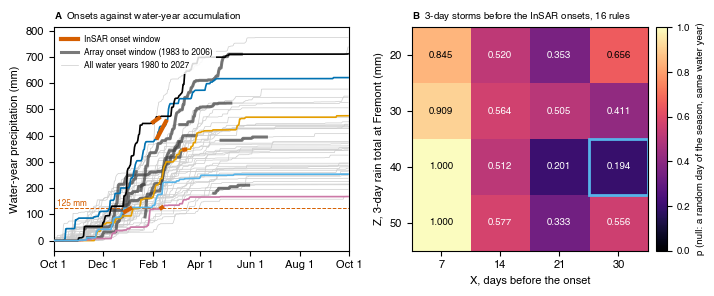

In [10]:
utils.mpl_paper_style(base=8)          # Helvetica, 8 pt, editable PDF text
insar_colour = insar_bar_colour         # Okabe-Ito vermillion: InSAR, as in every figure of 12 and 13
event_colours = ["#0072B2", "#E69F00", "#CC79A7", "#000000", "#56B4E9"]   # Okabe-Ito, no green
assert len(event_colours) >= n_insar, "more InSAR events than distinct colours"
array_years_text = f"{int(np.floor(aa_dense.onset_lo.min()))} to {int(np.floor(aa_dense.onset_hi.max()))}"
best_Y = int(best_rule_a.thr)
fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.0), width_ratios=[1.15, 1.0])
# a) every water year's accumulation, the InSAR event years in colour, the onset windows as thick segments
ax = axes[0]
for wy in range(wy_years[0], wy_years[1] + 1):
    this_year = wy_series(wy)
    ax.plot(this_year.dowy, this_year.cum, "-", color="0.8", lw=0.5, zorder=1)
for colour, event in zip(event_colours, insar_rain.itertuples()):
    this_year = wy_series(event.wy)
    ax.plot(this_year.dowy, this_year.cum, "-", color=colour, lw=1.2, zorder=3, label=f"WY{event.wy}")
    ax.plot([event.dowy_lo, event.dowy_hi], [event.cum_at_lo, event.cum_at_hi], "-", color=insar_colour, lw=3, solid_capstyle="butt", zorder=4)
for event in aa_rain.itertuples():
    this_year = wy_series(event.wy)
    segment = this_year[(this_year.dowy >= event.dowy_lo) & (this_year.dowy <= event.dowy_hi)]
    ax.plot(segment.dowy, segment.cum, "-", color="0.25", lw=2.2, alpha=0.7, zorder=2)
ax.axhline(best_rule_a.thr, color=insar_colour, lw=0.7, ls="--")
ax.text(5, best_rule_a.thr + 8, f"{best_rule_a.thr:.0f} mm", fontsize=6, color=insar_colour)
ax.set_xlim(1, 366)
ax.set_xticks([1, 62, 124, 182, 244, 305, 366])
ax.set_xticklabels(["Oct 1", "Dec 1", "Feb 1", "Apr 1", "Jun 1", "Aug 1", "Oct 1"])
ax.set_ylabel("Water-year precipitation (mm)")
ax.legend(handles=[Line2D([], [], color=insar_colour, lw=3, label="InSAR onset window"),
                   Line2D([], [], color="0.25", lw=2.2, alpha=0.7, label=f"Array onset window ({array_years_text})"),
                   Line2D([], [], color="0.8", lw=0.5, label=f"All water years {wy_years[0]} to {wy_years[1]}")], fontsize=6, loc="upper left")
utils.panel_title(ax, "A", "Onsets against water-year accumulation")
# b) the 3-day rainfall-total test: p of every setting (rows Z, columns X), the number written in each cell, the best outlined
ax = axes[1]
p_cmap = plt.get_cmap("magma")                       # sequential, no blue or green
image = ax.imshow(p_table.values, cmap=p_cmap, vmin=0, vmax=1, aspect="auto")
for i, Z in enumerate(p_table.index):
    for j, X in enumerate(p_table.columns):
        p_value = float(p_table.loc[Z, X])
        red, green, blue, _ = p_cmap(p_value)
        text_colour = "white" if 0.299 * red + 0.587 * green + 0.114 * blue < 0.5 else "black"     # readable on the cell's own colour
        ax.text(j, i, f"{p_value:.3f}", ha="center", va="center", fontsize=7, color=text_colour)
best_row = list(p_table.index).index(best_sweep.Z_mm)
best_column = list(p_table.columns).index(best_sweep.X_d)
ax.add_patch(plt.Rectangle((best_column - 0.5, best_row - 0.5), 1, 1, facecolor="none", edgecolor="#56B4E9", lw=2))   # Okabe-Ito sky blue
ax.set_xticks(range(len(p_table.columns)))
ax.set_xticklabels([f"{X}" for X in p_table.columns])
ax.set_yticks(range(len(p_table.index)))
ax.set_yticklabels([f"{Z}" for Z in p_table.index])
ax.set_xlabel("X, days before the onset")
ax.set_ylabel(f"Z, {rain_total_days}-day rain total at Fremont (mm)")
colour_bar = fig.colorbar(image, ax=ax, fraction=0.05, pad=0.03)
colour_bar.set_label("p (null: a random day of the season, same water year)", fontsize=7)
colour_bar.ax.tick_params(labelsize=7)
utils.panel_title(ax, "B", f"3-day storms before the InSAR onsets, {n_settings} rules")
fig.tight_layout()
f_conditioning = os.path.join(fig_dir, f"figS_precip_conditioning_bestY{best_Y}mm_rain{rain_total_days}d_sweep{n_settings}_nnull{n_null}.png")
fig.savefig(f_conditioning, dpi=300)
fig.savefig(f_conditioning.replace(".png", ".pdf"))
print("Saved figure to:", f_conditioning)
plt.show()

## 10. The summary read by 13_forecast: `rain_conditioning_summary.csv`

Part (3) of the prediction statement of 13_forecast and its data line quote the rainfall conditioning. The quantities
are written here, one row per scalar (name, value, unit, description), and 13_forecast reads them without recomputing
them. They are the onset days on the water year, the rainfall accumulated at the onsets, the percentiles of the
water-year totals, the rainfall-total test (best setting, its p and the search-corrected p), the lag spreads of the
tightest rules, the calendar spread, and the last day with a Fremont reading.

In [11]:
fremont_last_day = rain.index[(rain.src == "FREMONT") & rain.prcp_mm.notna()].max()
summary_rows = [
    ("n_insar_onsets", n_insar, "count", "InSAR onset windows"),
    ("onset_dowy_min", int(insar_rain.dowy_lo.min()), "d", "first day of water year of any InSAR onset window"),
    ("onset_dowy_max", int(insar_rain.dowy_hi.max()), "d", "last day of water year of any InSAR onset window"),
    ("onset_earliest", dowy_label(insar_rain.dowy_lo.min()), "date", "onset_dowy_min as 'Mon DD'"),
    ("onset_latest", dowy_label(insar_rain.dowy_hi.max()), "date", "onset_dowy_max as 'Mon DD'"),
    ("calendar_spread_d", calendar_spread, "d", "onset_dowy_max - onset_dowy_min"),
    ("cum_at_onset_min_mm", float(insar_rain.cum_at_lo.min()), "mm", "WY rain accumulated by the earliest window start"),
    ("cum_at_onset_max_mm", float(insar_rain.cum_at_hi.max()), "mm", "WY rain accumulated by the latest window end"),
    ("frac_at_onset_min", float(insar_rain.frac_at_lo.min()), "1", "fraction of the WY total by the earliest window start"),
    ("frac_at_onset_max", float(insar_rain.frac_at_hi.max()), "1", "fraction of the WY total by the latest window end"),
    ("wy_percentile_min", float((wy_total_series < insar_rain.wy_total_mm.min()).mean() * 100), "pct", "percentile of the driest InSAR event year"),
    ("wy_percentile_max", float((wy_total_series < insar_rain.wy_total_mm.max()).mean() * 100), "pct", "percentile of the wettest InSAR event year"),
    ("wy_first", complete_wy[0], "wy", "first water year of the WY-total distribution"),
    ("wy_last", complete_wy[1], "wy", "last water year of the WY-total distribution"),
    ("rain_total_days", rain_total_days, "d", "length of the running rain total"),
    ("rain_sweep_best_Z_mm", float(best_sweep.Z_mm), "mm", "best setting: 3-day total of at least Z mm"),
    ("rain_sweep_best_X_d", float(best_sweep.X_d), "d", "best setting: within X days before the onset"),
    ("rain_sweep_best_hits", float(best_sweep.hits), "count", "best setting: expected hits over the onset draws"),
    ("rain_sweep_best_null_hits", float(best_sweep.null_mean), "count", "best setting: hits of a random day of the same season"),
    ("rain_sweep_best_p", float(best_sweep.p), "1", "best setting's own p"),
    ("rain_sweep_p_search_paid", p_search_paid, "1", "p corrected for the search over all settings (the value to quote)"),
    ("rain_sweep_n_settings", n_settings, "count", "settings of Z and X swept"),
    ("ruleA_best_spread_d", float(best_rule_a.insar_lag_spread), "d", "tightest rule A: spread of the InSAR lags"),
    ("ruleB_best_spread_d", float(best_rule_b.insar_lag_spread), "d", "tightest rule B: spread of the InSAR lags"),
    ("fremont_last_valid_day", str(fremont_last_day.date()), "date", "last day with a Fremont reading in the rain series"),
]
rain_summary = pd.DataFrame(summary_rows, columns=["name", "value", "unit", "description"])
assert rain_summary.name.is_unique
rain_summary.to_csv(os.path.join(out_dir, "rain_conditioning_summary.csv"), index=False)
print(rain_summary.to_string(index=False))
print("saved rain_conditioning_summary.csv for 13_forecast")

                     name      value  unit                                                       description
           n_insar_onsets          5 count                                               InSAR onset windows
           onset_dowy_min         87     d                 first day of water year of any InSAR onset window
           onset_dowy_max        166     d                  last day of water year of any InSAR onset window
           onset_earliest     Dec 26  date                                        onset_dowy_min as 'Mon DD'
             onset_latest     Mar 15  date                                        onset_dowy_max as 'Mon DD'
        calendar_spread_d         79     d                                   onset_dowy_max - onset_dowy_min
      cum_at_onset_min_mm      106.1    mm                  WY rain accumulated by the earliest window start
      cum_at_onset_max_mm      471.5    mm                      WY rain accumulated by the latest window end
        frac_at_ons

## 11. The Fig 3 panels: the HRKT history and the onsets on the water year

Fig 3 is drawn by 14_paper_figures; its right column comes from 13_forecast, which computes the repeat intervals and
the forecast. This section saves the inputs of its left column. The rainfall grid has one column per water year and one row per day of the water year,
filled with the running 7-day total (`density_days`),

$$G(D, N) = \sum_{j=0}^{6} P(d - j),$$

where $d$ is the day $D$ of water year $N$ and missing days count as 0 mm. The column edges are placed at
$N - 1 + 273/365.25$, about 1 October. The section also saves the onset windows of both catalogues (with the day of
the water year of each window end) and the end of the bimonthly HRKT surveys, found as in `bimonthly_era` of 11.

In [12]:
# the rainfall grid: day of water year x water year, the running density_days-day total
rain_plot = rain[(rain.wy >= int(np.floor(x0)) + 1) & (rain.wy <= int(np.ceil(x1)))]
rain_7d = rain_plot.prcp_mm.fillna(0).rolling(density_days, min_periods=1).sum()
water_years = sorted(rain_plot.wy.unique())
rain_grid = np.full((367, len(water_years)), np.nan)          # day of water year x water year
x_edges = []
for j, wy in enumerate(water_years):
    this_year = rain_plot[rain_plot.wy == wy]
    rain_grid[this_year.dowy.values, j] = rain_7d[this_year.index].values
    x_edges.append(wy - 1 + 273 / 365.25)
x_edges.append(water_years[-1] + 273 / 365.25)
hrkt = utils.load_aa(common_paths["aa_dir"], "HRKT")
hrkt_stack = pd.read_csv(stacks_file).query("code == 'HRKT'")
# the bimonthly surveys end at the last HRKT survey that closes an interval of resolvable_days or less (as
# bimonthly_era in 11); the arrays were then surveyed annually until the start of the InSAR record
survey_gap_days = np.diff(hrkt.year.values) * 365.25
dense_era_end = float(hrkt.year.values[np.max(np.where(survey_gap_days <= resolvable_days)[0]) + 1])
insar_start = float(hrkt_stack.date.min())
print(f"bimonthly surveys at HRKT end {dense_era_end:.2f}; annual surveys from then until the InSAR record starts {insar_start:.2f}")
# the windows as local days (onset_days, the day convention); 14 draws them on the water year (dowy_lo, dowy_hi)
windows = onset_days[["src", "onset_lo", "onset_hi", "onset_mid", "day_lo", "day_hi", "utc_lo", "utc_hi", "window_day_basis"]].copy()
windows["dowy_lo"] = np.asarray(dowy(windows.day_lo))
windows["dowy_hi"] = np.asarray(dowy(windows.day_hi))
windows["day_lo"] = windows.day_lo.dt.strftime("%Y-%m-%d")
windows["day_hi"] = windows.day_hi.dt.strftime("%Y-%m-%d")
assert len(windows) == len(aa_dense) + len(insar_events) and windows[["dowy_lo", "dowy_hi"]].notna().all().all()
windows.to_csv(os.path.join(out_dir, "fig3_onset_windows.csv"), index=False)
np.savez(os.path.join(out_dir, "fig3_rain_panel.npz"), rain_grid=rain_grid, x_edges=np.asarray(x_edges), density_days=density_days,
         density_max=density_max, x0=x0, x1=x1, loma_prieta=loma_prieta, dense_era_end=dense_era_end, insar_start=insar_start,
         rain_colours=np.array(rain_colours), wet_season_months=np.array(wet_season_months))     # 13_forecast checks that it uses the same season
print("saved fig3_onset_windows.csv and fig3_rain_panel.npz for 13_forecast and 14_paper_figures")

bimonthly surveys at HRKT end 2007.44; annual surveys from then until the InSAR record starts 2016.67
saved fig3_onset_windows.csv and fig3_rain_panel.npz for 13_forecast and 14_paper_figures


## 12. Registry: the stats sidecar `12_rain_stats.txt` and the `12_*` numbers

In [13]:
stats_lines += ["", f"onset windows against the wet season ({wet_season_text}, months {wet_season_months}, {wet_season_source}; "
                f"{100 * wet_share.median():.0f} % of the year's rain): "
                f"{n_wet_inside} of {len(event_table)} wholly inside, {n_wet_partly} partly, {n_wet_outside} wholly outside; "
                f"InSAR {n_insar_wet_inside} of {is_insar.sum()} wholly inside"]
sidecar = REG.sidecar("12_rain", stats_lines)
REG.register("12_rain_series_start", str(days[0].date()), "date", 0, where="M9", cell="rain", sidecar=sidecar)
REG.register("12_rain_series_end", str(days[-1].date()), "date", 0, where="M9", cell="rain", sidecar=sidecar)
REG.register("12_wy_median_mm", complete_years.total_mm.median(), "mm", 0, where="M9", cell="rain", sidecar=sidecar)
REG.register("12_wy_p10_mm", complete_years.total_mm.quantile(.1), "mm", 0, where="M9", cell="rain", sidecar=sidecar)
REG.register("12_wy_p90_mm", complete_years.total_mm.quantile(.9), "mm", 0, where="M9", cell="rain", sidecar=sidecar)
REG.register("12_n_aa_season_resolved", len(aa_dense), "count", 0, where="Fig3 caption", cell="catalogues", sidecar=sidecar)
REG.register("12_n_events", len(event_table), "count", 0, where="P10", cell="seasonality", sidecar=sidecar)
# the season is part of the key (e.g. 12_n_wet_oct_apr_inside), so a different season gives different keys
REG.register(f"12_n_wet_{wet_season_tag}_inside", n_wet_inside, "count", 0, where="P10", cell="seasonality", sidecar=sidecar)
REG.register(f"12_n_wet_{wet_season_tag}_partly", n_wet_partly, "count", 0, where="P10", cell="seasonality", sidecar=sidecar)
REG.register(f"12_n_wet_{wet_season_tag}_outside", n_wet_outside, "count", 0, where="P10", cell="seasonality", sidecar=sidecar)
REG.register(f"12_n_insar_wet_{wet_season_tag}_inside", n_insar_wet_inside, "count", 0, where="P10", cell="seasonality", sidecar=sidecar)
REG.register(f"12_wet_{wet_season_tag}_rain_pct", 100 * wet_share.median(), "%", 0, where="P10", cell="seasonality", sidecar=sidecar)
# the rainfall conditioning (sections 7 and 8)
REG.register("12_insar_onset_dowy_min", int(insar_rain.dowy_lo.min()), "d", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("12_insar_onset_dowy_max", int(insar_rain.dowy_hi.max()), "d", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("12_insar_onset_earliest", dowy_label(insar_rain.dowy_lo.min()), "date", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("12_insar_onset_latest", dowy_label(insar_rain.dowy_hi.max()), "date", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("12_insar_onset_calendar_spread_d", calendar_spread, "d", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("12_insar_wy_total_min_mm", insar_rain.wy_total_mm.min(), "mm", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("12_insar_wy_total_max_mm", insar_rain.wy_total_mm.max(), "mm", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("12_insar_wy_percentile_min", (wy_total_series < insar_rain.wy_total_mm.min()).mean() * 100, "pct", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("12_insar_wy_percentile_max", (wy_total_series < insar_rain.wy_total_mm.max()).mean() * 100, "pct", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("12_insar_cum_at_onset_min_mm", insar_rain.cum_at_lo.min(), "mm", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("12_insar_cum_at_onset_max_mm", insar_rain.cum_at_hi.max(), "mm", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("12_insar_frac_at_onset_min", insar_rain.frac_at_lo.min(), "1", 2, where="P10", cell="conditioning", sidecar=sidecar)   # at the window start
REG.register("12_insar_frac_at_onset_max", insar_rain.frac_at_hi.max(), "1", 2, where="P10", cell="conditioning", sidecar=sidecar)
# the array onsets bound the fraction from both sides: the earliest array window end and the latest array window start
REG.register("12_aa_frac_at_onset_end_min", aa_rain.frac_at_hi.min(), "1", 2, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("12_aa_frac_at_onset_start_max", aa_rain.frac_at_lo.max(), "1", 2, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("12_ruleA_best_Y_mm", best_rule_a.thr, "mm", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("12_ruleA_lag_min_d", best_rule_a.insar_lag_min, "d", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("12_ruleA_lag_max_d", best_rule_a.insar_lag_max, "d", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("12_ruleB_best_Z_mm", best_rule_b.thr, "mm", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("12_ruleB_lag_min_d", best_rule_b.insar_lag_min, "d", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("12_ruleB_lag_max_d", best_rule_b.insar_lag_max, "d", 0, where="P10", cell="conditioning", sidecar=sidecar)
REG.register("12_rain_sweep_best_Z_mm", int(best_sweep.Z_mm), "mm", 0, where="P10", cell="rain sweep", sidecar=sidecar)
REG.register("12_rain_sweep_best_X_d", int(best_sweep.X_d), "d", 0, where="P10", cell="rain sweep", sidecar=sidecar)
REG.register("12_rain_sweep_best_hits", best_sweep.hits, "count", 2, where="P10", cell="rain sweep", sidecar=sidecar)
REG.register("12_rain_sweep_best_null_hits", best_sweep.null_mean, "count", 2, where="P10", cell="rain sweep", sidecar=sidecar)
REG.register("12_rain_sweep_best_p", best_sweep.p, "1", 3, where="P10", cell="rain sweep", sidecar=sidecar)
REG.register("12_rain_sweep_p_search_paid", p_search_paid, "1", 3, where="P10", cell="rain sweep", sidecar=sidecar)
REG.register("12_rain_sweep_n_settings", n_settings, "count", 0, where="P10", cell="rain sweep", sidecar=sidecar)
REG.render()

Saved stats to: /Users/dlindsay/work/proj_TulePond_DISP_release/outputs/12_rain_seasonality/12_rain_stats.txt
  registered 12_rain_series_start = 1978-10-01 date  -> M9
  registered 12_rain_series_end = 2026-11-03 date  -> M9
  registered 12_wy_median_mm = 362 mm  -> M9
  registered 12_wy_p10_mm = 219 mm  -> M9
  registered 12_wy_p90_mm = 567 mm  -> M9
  registered 12_n_aa_season_resolved = 9 count  -> Fig3 caption
  registered 12_n_events = 14 count  -> P10
  registered 12_n_wet_oct_apr_inside = 10 count  -> P10


  registered 12_n_wet_oct_apr_partly = 4 count  -> P10
  registered 12_n_wet_oct_apr_outside = 0 count  -> P10
  registered 12_n_insar_wet_oct_apr_inside = 5 count  -> P10
  registered 12_wet_oct_apr_rain_pct = 96 %  -> P10
  registered 12_insar_onset_dowy_min = 87 d  -> P10


  registered 12_insar_onset_dowy_max = 166 d  -> P10


  registered 12_insar_onset_earliest = Dec 26 date  -> P10


  registered 12_insar_onset_latest = Mar 15 date  -> P10
  registered 12_insar_onset_calendar_spread_d = 79 d  -> P10
  registered 12_insar_wy_total_min_mm = 168 mm  -> P10
  registered 12_insar_wy_total_max_mm = 712 mm  -> P10
  registered 12_insar_wy_percentile_min = 0 pct  -> P10
  registered 12_insar_wy_percentile_max = 93 pct  -> P10
  registered 12_insar_cum_at_onset_min_mm = 106 mm  -> P10


  registered 12_insar_cum_at_onset_max_mm = 472 mm  -> P10
  registered 12_insar_frac_at_onset_min = 0.42 1  -> P10
  registered 12_insar_frac_at_onset_max = 0.78 1  -> P10
  registered 12_aa_frac_at_onset_end_min = 0.42 1  -> P10
  registered 12_aa_frac_at_onset_start_max = 0.94 1  -> P10


  registered 12_ruleA_best_Y_mm = 125 mm  -> P10


  registered 12_ruleA_lag_min_d = -8 d  -> P10


  registered 12_ruleA_lag_max_d = 70 d  -> P10
  registered 12_ruleB_best_Z_mm = 15 mm  -> P10
  registered 12_ruleB_lag_min_d = 33 d  -> P10
  registered 12_ruleB_lag_max_d = 125 d  -> P10
  registered 12_rain_sweep_best_Z_mm = 40 mm  -> P10
  registered 12_rain_sweep_best_X_d = 30 d  -> P10
  registered 12_rain_sweep_best_hits = 5.00 count  -> P10
  registered 12_rain_sweep_best_null_hits = 3.68 count  -> P10


  registered 12_rain_sweep_best_p = 0.194 1  -> P10
  registered 12_rain_sweep_p_search_paid = 0.501 1  -> P10
  registered 12_rain_sweep_n_settings = 16 count  -> P10
Wrote the numbers to: /Users/dlindsay/work/proj_TulePond_DISP_release/outputs/paper_numbers.md


'/Users/dlindsay/work/proj_TulePond_DISP_release/outputs/paper_numbers.md'